# 05 — Candidate solutions and held-out angular noise

**Question.** Which practical changes address slow random assembly, insufficient temporal resolution, and reproducible future sensing comparisons? The three main candidates are longer observation, finer internal updates, and saved assembled starting states. None is assumed to solve all three problems.

This notebook also tests the exploratory noise hypothesis on **20 new seeds (30–49)**, excluded from the original ten-seed sensitivity study and the new 30-seed reference cohort. There is no light mechanism, parameter optimization, global attraction, or replacement of random initialization.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_two"
PAPERS_DIR = MODEL_DIR
STUDY_DIR = HERE

import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from shiner_model import GoldenShinersModel
from handlings.trial_two.study_support import run_streamed

DATA_DIR, FIGURE_DIR = STUDY_DIR / "data", STUDY_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CONFIG = {"seeds": list(range(30, 50)), "duration_s": 180.0,
          "speed_BL_s": 1.0, "dt_s": 0.125, "record_interval_s": 1.0,
          "conditions": {"Reference": 0.0, "Angular noise 0.01": 0.01},
          "assembly_definition": "one connected component for at least 5 simulated seconds"}
SUMMARY_PATH = DATA_DIR / "05_noise_holdout_summary.csv"
TRACE_PATH = DATA_DIR / "05_noise_holdout_traces.csv"
MANIFEST_PATH = DATA_DIR / "05_noise_holdout_manifest.json"

def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

from handlings.trial_one.relocation import executed_source_hashes

SOURCE_PATHS = [PAPERS_DIR / "shiner_model.py", STUDY_DIR / "study_support.py",
                MODEL_DIR / "handlings/trial_one/diagnostics.py"]
SOURCE_HASHES = executed_source_hashes(SOURCE_PATHS, MODEL_DIR)


## Held-out protocol and transparent result cache

For each seed, both conditions have exactly the same uniformly random positions, random headings, arena, speed, social radii, perception, and unrestricted turning. Only `angular_noise` differs. At the reference timestep, 0.01 means an angular standard deviation of 0.01 rad per social update. Noise changes the fish model, unlike a longer observation horizon or a checkpoint protocol.

Every case runs for 180 simulated seconds. Connectivity is assessed every **0.125-s internal update**, although summary traces and DataCollector records are saved once per second. The operational assembly definition is one connected component continuously for at least five seconds. Assembly onset is backdated only after that requirement has actually been confirmed; unconfirmed runs are right-censored at 180 s.

The cell below contains the complete simulation procedure. It reuses saved results only when the full configuration, model/helper/diagnostics source SHA-256 values, and both output-file hashes agree. Delete the three `05_noise_holdout_*` cache files to recompute the 40 simulations. Reloading a verified cache in a fresh kernel recomputes all comparisons and figures without repeating the trajectories.

In [2]:
def initial_state_hash(seed, angular_noise):
    model = GoldenShinersModel(seed=seed, speed=CONFIG["speed_BL_s"],
                               dt=CONFIG["dt_s"], angular_noise=angular_noise)
    state = np.array([np.r_[f.position, f.direction, f.speed] for f in model.agents], dtype="<f8")
    return hashlib.sha256(state.tobytes()).hexdigest()

def cache_is_valid():
    if not all(p.is_file() for p in (SUMMARY_PATH, TRACE_PATH, MANIFEST_PATH)):
        return False
    previous = json.loads(MANIFEST_PATH.read_text())
    return (previous.get("configuration") == CONFIG and
            previous.get("source_sha256") == SOURCE_HASHES and
            previous.get("summary_sha256") == file_sha256(SUMMARY_PATH) and
            previous.get("trace_sha256") == file_sha256(TRACE_PATH))

if cache_is_valid():
    noise_results = pd.read_csv(SUMMARY_PATH)
    noise_traces = pd.read_csv(TRACE_PATH)
    print("Loaded verified cache: 40 executed held-out simulations; configuration, sources and outputs match.")
else:
    rows, traces = [], []
    for seed in CONFIG["seeds"]:
        initial_hashes = {name: initial_state_hash(seed, noise)
                          for name, noise in CONFIG["conditions"].items()}
        assert len(set(initial_hashes.values())) == 1, "Matched initial states must be identical."
        for condition, noise in CONFIG["conditions"].items():
            summary, trace, _ = run_streamed(
                seed, duration=CONFIG["duration_s"], speed=CONFIG["speed_BL_s"],
                dt=CONFIG["dt_s"], record_interval=CONFIG["record_interval_s"],
                angular_noise=noise,
            )
            rows.append({"Condition": condition, "AngularNoise": noise,
                         "InitialStateSHA256": initial_hashes[condition], **summary})
            traces.append(trace.assign(Condition=condition, Seed=seed, AngularNoise=noise))
        print(f"Completed matched seed {seed}: {2 * (seed - CONFIG['seeds'][0] + 1)}/40 simulations.", flush=True)
    assert SOURCE_HASHES == executed_source_hashes(SOURCE_PATHS, MODEL_DIR), \
        "Source changed during the experiment; results must be regenerated."
    noise_results = pd.DataFrame(rows)
    noise_traces = pd.concat(traces, ignore_index=True)
    noise_results.to_csv(SUMMARY_PATH, index=False)
    noise_traces.to_csv(TRACE_PATH, index=False)
    manifest = {"configuration": CONFIG, "source_sha256": SOURCE_HASHES,
                "summary_sha256": file_sha256(SUMMARY_PATH),
                "trace_sha256": file_sha256(TRACE_PATH), "simulation_count": len(rows),
                "provenance": "Executed from random initialization; no trajectory selection or early stopping."}
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2) + "\n")

assert len(noise_results) == 40
assert set(noise_results.Seed) == set(range(30, 50))
assert noise_results.groupby("Seed").InitialStateSHA256.nunique().eq(1).all()
assert noise_results.groupby("Condition").Seed.nunique().eq(20).all()
assert noise_results.InternalUpdates.eq(1440).all()
assert noise_results.Duration_s.eq(180).all()
assert noise_results.dt.eq(0.125).all()
print(f"Verified {len(noise_results)} cases, {int(noise_results.InternalUpdates.sum()):,} internal updates and identical paired starting states.")

Loaded verified cache: 40 executed held-out simulations; configuration, sources and outputs match.
Verified 40 cases, 57,600 internal updates and identical paired starting states.


In [3]:
noise_comparison = noise_results.groupby("Condition", sort=False).agg(
    Seeds=("Seed", "count"), Assembled=("AssemblySuccess", "sum"),
    Censored=("Censored", "sum"), FinalConnected=("FinalGroups", lambda s: int(s.eq(1).sum())),
    MeanConnectedTimeFraction=("ConnectedTimeFraction", "mean"),
    MeanLateLargestGroupFraction=("LateLargestGroupFraction", "mean"),
    MeanLatePolarization=("Polarization", "mean"),
    PostAssemblyBreakupRuns=("PostAssemblyBreakup", "sum"),
    MissedRepulsionPassesPerSecond=("MissedRepulsionPassesPerSecond", "mean"),
)
noise_comparison["AssemblyFraction"] = noise_comparison.Assembled / noise_comparison.Seeds
# Restricted time-to-confirmation includes censoring; do not average successful runs alone.
noise_results["RestrictedConfirmationTime"] = noise_results.AssemblyConfirmedTime.fillna(CONFIG["duration_s"])
noise_comparison["MeanRestrictedConfirmationTime_s"] = noise_results.groupby("Condition", sort=False).RestrictedConfirmationTime.mean()
noise_comparison.to_csv(DATA_DIR / "05_noise_holdout_comparison.csv")
display(noise_comparison.round(4))

paired = noise_results.pivot(index="Seed", columns="Condition", values=[
    "AssemblySuccess", "LateLargestGroupFraction", "ConnectedTimeFraction", "RestrictedConfirmationTime"])
base_success = paired["AssemblySuccess"]["Reference"].astype(bool)
noise_success = paired["AssemblySuccess"]["Angular noise 0.01"].astype(bool)
noise_only = int((noise_success & ~base_success).sum())
reference_only = int((base_success & ~noise_success).sum())
paired_effects = pd.DataFrame({
    "Seed": paired.index,
    "ReferenceAssembled": base_success.to_numpy(),
    "NoiseAssembled": noise_success.to_numpy(),
    "ChangeLateLargestGroupFraction": (paired["LateLargestGroupFraction"]["Angular noise 0.01"] - paired["LateLargestGroupFraction"]["Reference"]).to_numpy(),
    "ChangeConnectedTimeFraction": (paired["ConnectedTimeFraction"]["Angular noise 0.01"] - paired["ConnectedTimeFraction"]["Reference"]).to_numpy(),
    "ChangeRestrictedConfirmationTime_s": (paired["RestrictedConfirmationTime"]["Angular noise 0.01"] - paired["RestrictedConfirmationTime"]["Reference"]).to_numpy(),
})
paired_effects.to_csv(DATA_DIR / "05_noise_holdout_paired_effects.csv", index=False)
print(f"Discordant matched pairs: noise-only assembly={noise_only}; reference-only assembly={reference_only}.")
print("Censored reference seeds:", noise_results.query("Condition == 'Reference' and Censored").Seed.tolist())
print("Censored noise seeds:", noise_results.query("Condition == 'Angular noise 0.01' and Censored").Seed.tolist())
display(paired_effects.round(4))

,Seeds,Assembled,Censored,FinalConnected,MeanConnectedTimeFraction,MeanLateLargestGroupFraction,MeanLatePolarization,PostAssemblyBreakupRuns,MissedRepulsionPassesPerSecond,AssemblyFraction,MeanRestrictedConfirmationTime_s
Condition,,,,,,,,,,,
Reference,20,20,0,20,0.8068,1.000,0.9523,0,0.0147,1.00,39.8812
Angular noise 0.01,20,19,1,19,0.7645,0.985,0.9384,1,0.0097,0.95,45.7562


Discordant matched pairs: noise-only assembly=0; reference-only assembly=1.
Censored reference seeds: []
Censored noise seeds: [48]


,Seed,ReferenceAssembled,NoiseAssembled,ChangeLateLargestGroupFraction,ChangeConnectedTimeFraction,ChangeRestrictedConfirmationTime_s
0,30,True,True,0.0,0.076389,-13.75
1,31,True,True,0.0,-0.000694,0.125
2,32,True,True,0.0,0.260417,-46.875
3,33,True,True,0.0,0.0,0.0
4,34,True,True,0.0,-0.201389,36.25
5,35,True,True,0.0,0.013889,-2.5
6,36,True,True,0.0,-0.165972,0.0
7,37,True,True,0.0,0.097222,-17.5
8,38,True,True,0.0,0.0,0.0
9,39,True,True,0.0,-0.269444,48.5


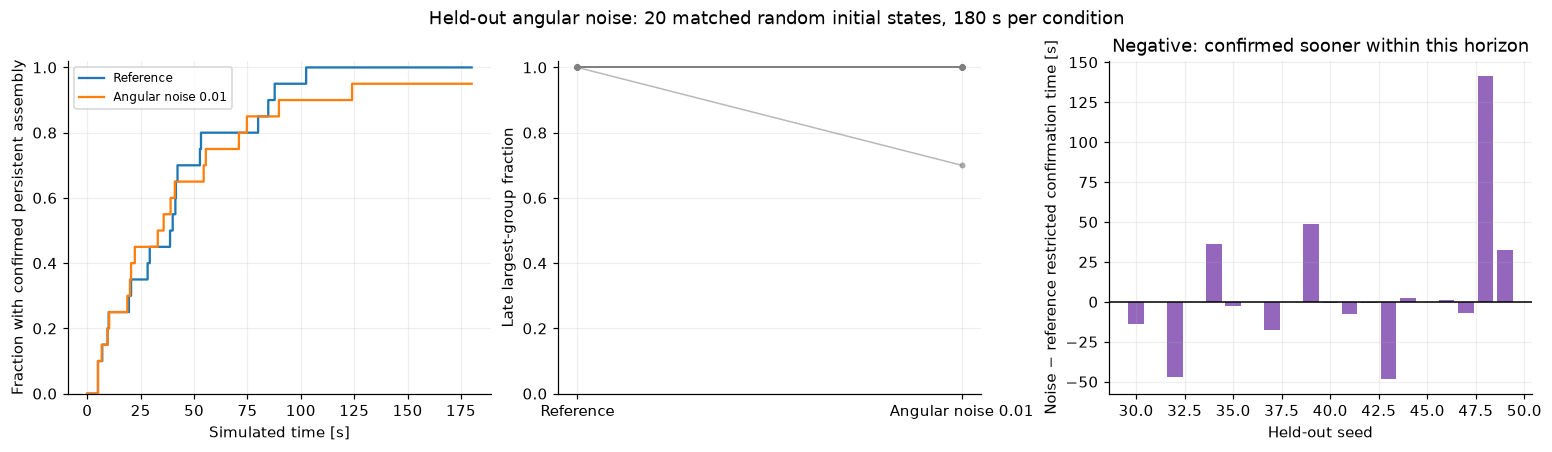

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
time_grid = np.linspace(0, CONFIG["duration_s"], 721)
colors = {"Reference": "tab:blue", "Angular noise 0.01": "tab:orange"}
for condition, group in noise_results.groupby("Condition", sort=False):
    confirmation = group.AssemblyConfirmedTime.to_numpy()
    fraction = np.array([np.sum(confirmation <= t) / len(group) for t in time_grid])
    axes[0].step(time_grid, fraction, where="post", label=condition, color=colors[condition])
axes[0].set(xlabel="Simulated time [s]", ylabel="Fraction with confirmed persistent assembly", ylim=(0, 1.02))
axes[0].legend(fontsize=8)
for _, row in paired_effects.iterrows():
    values = [float(paired["LateLargestGroupFraction"].loc[row.Seed, name]) for name in colors]
    axes[1].plot([0, 1], values, "o-", alpha=0.55, color="0.5", linewidth=1, markersize=3)
axes[1].set(xticks=[0, 1], xticklabels=list(colors), ylabel="Late largest-group fraction", ylim=(0, 1.02))
axes[2].axhline(0, color="black", linewidth=1)
axes[2].bar(paired_effects.Seed, paired_effects.ChangeRestrictedConfirmationTime_s, color="tab:purple")
axes[2].set(xlabel="Held-out seed", ylabel="Noise − reference restricted confirmation time [s]",
            title="Negative: confirmed sooner within this horizon")
for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle("Held-out angular noise: 20 matched random initial states, 180 s per condition")
fig.savefig(FIGURE_DIR / "05_noise_holdout.png", dpi=160)
plt.show()

In [5]:
ref = noise_comparison.loc["Reference"]
noisy = noise_comparison.loc["Angular noise 0.01"]
delta = noisy.AssemblyFraction - ref.AssemblyFraction
if delta > 0:
    direction = "a higher observed assembly fraction"
elif delta < 0:
    direction = "a lower observed assembly fraction"
else:
    direction = "the same observed assembly fraction"
notes = f"""### Held-out findings

- Reference: **{int(ref.Assembled)}/20** persistent assemblies; angular noise: **{int(noisy.Assembled)}/20**. Noise gives {direction} over this finite 180-s horizon ({delta * 100:+.1f} percentage points).
- The discordant pairs are **{noise_only} noise-only** versus **{reference_only} reference-only** assemblies. These counts show whether aggregate improvement hides seeds that become worse.
- Mean restricted confirmation time (a censored case contributes 180 s) is **{ref.MeanRestrictedConfirmationTime_s:.2f} s** for reference and **{noisy.MeanRestrictedConfirmationTime_s:.2f} s** for noise. This is a finite-horizon summary, not an uncensored mean assembly time.
- Post-assembly breakup occurs in **{int(ref.PostAssemblyBreakupRuns)}/{int(ref.Assembled)}** assembled reference runs and **{int(noisy.PostAssemblyBreakupRuns)}/{int(noisy.Assembled)}** noisy runs within their remaining observed follow-up.

**Decision:** retain the deterministic reference model. The 20 held-out seeds provide a new exploratory comparison, not sufficient empirical calibration or a guarantee across timestep, speed, arena and persistence definitions. The earlier 9/10 final-connected result alone does not justify adopting noise. Even a positive assembly result would not resolve high-speed timestep error. No noise amplitude is tuned here. The noisy run for seed 36 has one post-assembly disconnection before ending reconnected; seed 48 remains unassembled at the horizon, ending as 14 + 6.
"""
display(Markdown(notes))
noise_findings = {"seeds_per_condition": 20, "duration_s": CONFIG["duration_s"],
                  "reference_assembled": int(ref.Assembled), "noise_assembled": int(noisy.Assembled),
                  "reference_censored": int(ref.Censored), "noise_censored": int(noisy.Censored),
                  "noise_only_assembly_pairs": noise_only, "reference_only_assembly_pairs": reference_only,
                  "reference_postassembly_breakups": int(ref.PostAssemblyBreakupRuns),
                  "noise_postassembly_breakups": int(noisy.PostAssemblyBreakupRuns),
                  "reference_censored_seeds": noise_results.query("Condition == 'Reference' and Censored").Seed.tolist(),
                  "noise_censored_seeds": noise_results.query("Condition == 'Angular noise 0.01' and Censored").Seed.tolist(),
                  "noise_breakup_seeds": noise_results.query("Condition == 'Angular noise 0.01' and PostAssemblyBreakup").Seed.tolist(),
                  "reference_restricted_confirmation_mean_s": float(ref.MeanRestrictedConfirmationTime_s),
                  "noise_restricted_confirmation_mean_s": float(noisy.MeanRestrictedConfirmationTime_s),
                  "adopt_noise": False, "recommendation": "Retain reference; noise remains exploratory."}
(DATA_DIR / "05_noise_holdout_findings.json").write_text(json.dumps(noise_findings, indent=2) + "\n")

### Held-out findings

- Reference: **20/20** persistent assemblies; angular noise: **19/20**. Noise gives a lower observed assembly fraction over this finite 180-s horizon (-5.0 percentage points).
- The discordant pairs are **0 noise-only** versus **1 reference-only** assemblies. These counts show whether aggregate improvement hides seeds that become worse.
- Mean restricted confirmation time (a censored case contributes 180 s) is **39.88 s** for reference and **45.76 s** for noise. This is a finite-horizon summary, not an uncensored mean assembly time.
- Post-assembly breakup occurs in **0/20** assembled reference runs and **1/19** noisy runs within their remaining observed follow-up.

**Decision:** retain the deterministic reference model. The 20 held-out seeds provide a new exploratory comparison, not sufficient empirical calibration or a guarantee across timestep, speed, arena and persistence definitions. The earlier 9/10 final-connected result alone does not justify adopting noise. Even a positive assembly result would not resolve high-speed timestep error. No noise amplitude is tuned here. The noisy run for seed 36 has one post-assembly disconnection before ending reconnected; seed 48 remains unassembled at the horizon, ending as 14 + 6.


620

## Compare the three practical approaches

The following table reads the executed evidence from notebooks 01–04. **Longer observation** changes the assembly protocol, **finer timesteps** change the numerical realization of the same stated social rules, and **checkpoints** condition a future experiment on prior social assembly. Checkpoint conditioning changes the scientific population being compared, so the separate random-start assembly results remain essential.

In [6]:
long_horizon = pd.read_csv(DATA_DIR / "01_long_horizon_summary.csv")
refinement = pd.read_csv(DATA_DIR / "02_refinement_comparison.csv")
checkpoints = pd.read_csv(DATA_DIR / "04_checkpoint_validation.csv")
assert len(long_horizon) >= 30
assert checkpoints[["StateRoundTripExact", "OriginalContinuationExact", "PairedControlsExact"]].all().all()
long_success = int(long_horizon.AssemblySuccess.sum())
long_censored = int(long_horizon.Censored.sum())
additional_after_old_horizon = int((long_horizon.AssemblySuccess & (long_horizon.AssemblyConfirmedTime > 62.5)).sum())

approaches = pd.DataFrame([
    {"Approach": "Longer random-start observation", "Addresses": "Finite-horizon censoring of slow assembly",
     "Changes fish behaviour?": "No; experimental duration only",
     "Executed evidence": f"{long_success}/{len(long_horizon)} assembled by 180 s; {long_censored} right-censored; {additional_after_old_horizon} confirmations after 62.5 s",
     "Advantages": "Retains random assembly question and quantifies delays",
     "Limitations": "Finite horizon and seeds; cost grows linearly; not a numerical-resolution fix",
     "Recommendation": "Keep random initialization as Part 1; report censoring"},
    {"Approach": "Finer internal timestep", "Addresses": "Social zones crossed between high-speed updates",
     "Changes fish behaviour?": "Same rule equations; changes their numerical discretization",
     "Executed evidence": f"Matched 0.0625/0.03125/0.015625-s comparison; {len(refinement)} convergence-table rows (see 02)",
     "Advantages": "Separates internal physics from convenient recording frequency",
     "Limitations": "More updates; convergence must be shown quantitatively at each speed",
     "Recommendation": "Use notebook 02 decision; do not assume 0.03125 s is sufficient"},
    {"Approach": "Saved assembled checkpoint", "Addresses": "Unequal initial connectivity in a future paired light/control experiment",
     "Changes fish behaviour?": "No; conditions future comparison on assembly",
     "Executed evidence": f"{len(checkpoints)} exact state reloads, original-continuation checks and paired constant-speed controls",
     "Advantages": "Same positions, headings, parameters, absolute step and RNG state in paired branches",
     "Limitations": "Conditions on successful assembly; saved reference-dt states do not validate another timestep or light mechanism",
     "Recommendation": "Use validated assembled checkpoints for Part 2 after numerical readiness"},
    {"Approach": "Small angular noise (exploratory)", "Addresses": "Hypothesized escape from persistent subgroup trajectories",
     "Changes fish behaviour?": "Yes; adds stochastic angular error",
     "Executed evidence": f"20 held-out pairs: {int(ref.Assembled)}/20 reference vs {int(noisy.Assembled)}/20 noisy assemblies",
     "Advantages": "Tests a hypothesis on seeds excluded from discovery",
     "Limitations": "One amplitude, speed and timestep; no empirical fit; still finite-horizon censoring",
     "Recommendation": "Do not adopt automatically; retain the reference model"},
])
approaches.to_csv(DATA_DIR / "05_candidate_comparison.csv", index=False)
display(approaches)
print("Numerical refinement table from notebook 02:")
display(refinement.round(5))

,Approach,Addresses,Changes fish behaviour?,Executed evidence,Advantages,Limitations,Recommendation
0,Longer random-start observation,Finite-horizon censoring of slow assembly,No; experimental duration only,30/30 assembled by 180 s; 0 right-censored; 6 ...,Retains random assembly question and quantifie...,Finite horizon and seeds; cost grows linearly;...,Keep random initialization as Part 1; report c...
1,Finer internal timestep,Social zones crossed between high-speed updates,Same rule equations; changes their numerical d...,Matched 0.0625/0.03125/0.015625-s comparison; ...,Separates internal physics from convenient rec...,More updates; convergence must be shown quanti...,Use notebook 02 decision; do not assume 0.0312...
2,Saved assembled checkpoint,Unequal initial connectivity in a future paire...,No; conditions future comparison on assembly,"30 exact state reloads, original-continuation ...","Same positions, headings, parameters, absolute...",Conditions on successful assembly; saved refer...,Use validated assembled checkpoints for Part 2...
3,Small angular noise (exploratory),Hypothesized escape from persistent subgroup t...,Yes; adds stochastic angular error,20 held-out pairs: 20/20 reference vs 19/20 no...,Tests a hypothesis on seeds excluded from disc...,"One amplitude, speed and timestep; no empirica...",Do not adopt automatically; retain the referen...


Numerical refinement table from notebook 02:


,Speed,Metric,MeanAt03125,MeanAt015625,EnsembleAbsoluteChange,EnsembleRelativeChange,PairedAbsoluteChange,PairedRelativeChange,MatchedTimeMAE,Tolerance,ToleranceUnits,EnsemblePass,PairedPass,MetricPass
0,1.0,Polarization,0.92909,0.96014,0.03104,0.03233,0.03104,0.03233,0.04679,0.10,relative,True,True,True
1,1.0,LargestGroupFraction,0.97000,0.97690,0.00690,0.00706,0.00690,0.00706,0.00690,0.05,absolute,True,True,True
2,1.0,MeanNND,0.72900,0.58388,0.14512,0.24854,0.14526,0.24878,0.14662,0.10,relative,False,False,False
3,1.0,MeanDistanceToCentroid,1.65115,1.65313,0.00197,0.00119,0.40975,0.24786,0.41556,0.10,relative,True,False,False
4,3.0,Polarization,0.96046,0.85054,0.10992,0.12924,0.15245,0.17924,0.17367,0.10,relative,False,False,False
5,3.0,LargestGroupFraction,0.99000,0.90000,0.09000,0.10000,0.11000,0.12222,0.11000,0.05,absolute,False,False,False
6,3.0,MeanNND,0.69759,0.53642,0.16117,0.30045,0.16117,0.30045,0.16234,0.10,relative,False,False,False
7,3.0,MeanDistanceToCentroid,1.25413,2.38146,1.12733,0.47338,1.60719,0.67488,1.60761,0.10,relative,False,False,False
8,5.0,Polarization,0.94370,0.94612,0.00241,0.00255,0.05040,0.05327,0.09763,0.10,relative,True,True,True
9,5.0,LargestGroupFraction,1.00000,0.98040,0.01960,0.01999,0.01960,0.01999,0.01960,0.05,absolute,True,True,True


## What the comparisons mean

These approaches address different questions and may ultimately be used together. Longer observation can reveal delayed assembly without altering the social model. It cannot fix unresolved fast motion. Checkpoints make future paired experiments reproducible but do not make the censored random-start runs disappear and do not establish biological realism. A numerical refinement that changes collective metrics is a warning about resolution, even when connectivity looks attractive.

**Literature motivation versus project evidence.** [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065) motivate the local social rules. [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9) provide the golden-shiner parameter context and future high-speed range; the optional noise test here remains a project hypothesis. [Berdahl et al. (2013)](https://doi.org/10.1126/science.1225883) motivate the later collective-sensing question. Exact five-second persistence, the 180-s horizon, held-out seed partition and source-hashed result cache are explicit project conventions, not literature-derived biological constants.

Finite samples, a finite observation horizon, graph-based connectivity, variable post-assembly follow-up, absence of subgroup lineage tracking, and lack of empirical assembly-time calibration limit the conclusions. Light has not been added. Notebook 06 combines these results into the readiness decision.